# Quantum Computing Models from Two Papers — Reproductions in Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saurabhkulkarni77/quantum-ml-papers/blob/main/Quantum_Models_from_Papers.ipynb)


This notebook implements the quantum models of two published papers, using experimental data **according to the papers**, and compares the reproduction against the papers' reported numbers.

| # | Paper | Model reproduced |
|---|-------|------------------|
| A | H.-K. Cheng, P.-Y. Yang, J.-P. Chou & C.-W. Pao, *Predicting Complex Materials Energetics with a Scalable Compact Nine-Qubit Quantum Machine-Learning Model*, **PRX Energy 5, 013004 (2026)** | 9-qubit **QCNN** (99 parameters) and **QDNN** (63 parameters) predicting DFT total energies of a Li-intercalated Pb-BTC metal-organic framework from bispectrum descriptors |
| B | T. Matsumori, M. Taki & T. Kadowaki, *Application of QUBO solver using black-box optimization to structural design for resonance avoidance*, **Scientific Reports 12, 12143 (2022)** | **FM-QUBO**: factorization-machine black-box optimization with a QUBO solver (simulated annealing) for PCB mounting-hole design, vs the paper's BOCS-QUBO and random-search baselines |

**How to run:** Runtime → Run all. Everything runs on a CPU runtime (statevector simulators only; no quantum hardware calls). A full run takes roughly **1.5 hours**, dominated by Paper B's 20-run optimization benchmarks, which follow the paper's protocol exactly. Every cell also runs standalone in order — the printed outputs in this saved notebook are from a complete execution.

**Data provenance (details in each part):**
- **Paper A** — the authors' own public demo repository (https://github.com/Hsu-Kai/qcnn-energy-demo) ships the paper's Pb-BTC MOF dataset: 1,219 DFT-labelled structures (`PbMOF.db`) and their precomputed bispectrum descriptors. We use that data as-is. The paper's alloy dataset is *not* public (the paper's data-availability statement says so), so the alloy system is not reproduced — only the MOF system is.
- **Paper B** — there is no external dataset: the paper's data are generated by its finite-element frequency analysis. The paper's exact PCB dimensions/materials are in its supplementary file, not the main text, so an exact numeric reproduction of its frequencies is impossible from the paper alone. We therefore generate the data with a **simplified plate modal model, clearly labelled as a stand-in** for the paper's CalculiX FEM model, and run the paper's FM-QUBO algorithm and evaluation protocol on it unchanged. Absolute frequencies differ from the paper's; the algorithm comparison (success ratios) is the reproduced result.

## 0 · Setup

Pinned installs (versions follow the Paper A demo repository's `requirements.txt`, with patch-level updates verified for this notebook; `autoray` is pinned because PennyLane 0.38 is incompatible with autoray ≥ 0.7). Fixed seeds throughout.

In [1]:
import sys, subprocess
PINS = ["numpy==1.26.4", "scipy==1.14.1", "matplotlib==3.9.2", "scikit-learn==1.5.2",
        "pandas==2.2.2", "pennylane==0.38.0", "autoray==0.6.11",
        "jax[cpu]==0.4.35", "jaxlib==0.4.35", "optax==0.2.3",
        "ase==3.23.0", "dwave-neal==0.6.0"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + PINS, check=True)
print("installed:", ", ".join(PINS))

installed: numpy==1.26.4, scipy==1.14.1, matplotlib==3.9.2, scikit-learn==1.5.2, pandas==2.2.2, pennylane==0.38.0, autoray==0.6.11, jax[cpu]==0.4.35, jaxlib==0.4.35, optax==0.2.3, ase==3.23.0, dwave-neal==0.6.0


In [2]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
print("numpy", np.__version__)

numpy 1.26.4


---
# Part A — Nine-qubit quantum machine learning for materials energies

**Paper:** Hsu-Kai Cheng, Po-Yu Yang, Jyh-Pin Chou, and Chun-Wei Pao, "Predicting Complex Materials Energetics with a Scalable Compact Nine-Qubit Quantum Machine-Learning Model," *PRX Energy* **5**, 013004 (2026). DOI: 10.1103/j1lk-1cvs.

**The model, in brief.**
1. **Descriptors.** Each atom's local environment is encoded in bispectrum components with $J_{\max}=4$ → 55 numbers per atom.
2. **Feature condensation.** Per-atom descriptors are summed over atoms of the same element type, giving a fixed-length *feature spectrum* of $55 \times 5 = 275$ numbers for any structure (both of the paper's systems contain 5 element species), independent of system size.
3. **Encoding.** The 275-vector is amplitude-encoded into **9 qubits** ($2^9 = 512$ amplitudes, the rest zero-padded).
4. **Models.** A **QCNN** (quantum convolutional neural network; convolution + pooling layers with weight sharing, **99 trainable parameters**) and a **QDNN** (quantum deep neural network; a single quantum neural-network layer — encoder, transformation, output — **63 trainable parameters**). The prediction is the expectation value of the local observable $H = \sigma_z^{(1)}$ on the first qubit, mapped onto the DFT total energy.
5. **Training.** Loss = RMSE against DFT total energies **per atom**; PennyLane simulator + Adam optimizer (JAX/optax). Protocol: **400 training / 100 test structures**, randomly sampled. Labels come from VASP DFT (PAW, 400 eV cutoff, 3×3×3 k-point mesh, DFT-D3 dispersion).

**Paper's headline results.** Test RMSE ≈ **0.05 eV/atom** on the Co₂₅Ni₂₅(HfTiZr)₅₀ high-entropy alloy and ≈ **0.04 eV/atom** on the Li-intercalated Pb-BTC MOF, for the trained QML models. (The paper also reports normalized effective dimensions $d_{400}$: QCNN 0.64 / QDNN 0.78 (alloy), QCNN 0.64 / QDNN 0.75 (MOF) — a model-capacity diagnostic we do not reproduce here.)

**What we reproduce.** The MOF system, end-to-end, on the authors' own data (next section): the exact QCNN circuit from the authors' demo code, and a QDNN that follows the paper's description (single QNNL with encoder/transformation/output stages, exactly 63 parameters — the paper's gate-level QDNN layout is in its Supplemental Material, which we do not have, so the QDNN is an honest reconstruction at the paper's parameter count, not a claim of gate identity). Classical baselines of the kind the paper contrasts against (linear regression and a shallow neural network on the same 275 features) are included.

## A.1 · Data — the authors' public Pb-BTC MOF dataset

The paper's data-availability statement says the supporting data are *not publicly available* (authors on reasonable request). However, the paper points to public sample code for the Pb-MOF system, and that repository — https://github.com/Hsu-Kai/qcnn-energy-demo (Hsu-Kai Cheng) — ships real data files, which we use unchanged:

- `PbMOF.db` — ASE database of **1,219 structures** of Li-intercalated Pb-BTC MOF with DFT total energies (the paper's labels: VASP/PAW, 400 eV, 3×3×3 k-mesh, DFT-D3).
- `bispectrum_PbMOF.npy` — the precomputed per-structure bispectrum feature spectra (1,219 × 275), aligned row-by-row with the database — i.e., exactly the condensed feature spectra of the paper's §II.B.

The alloy dataset (Co₂₅Ni₂₅(HfTiZr)₅₀) is **not** in the repository and not public, so — as flagged in the introduction — only the MOF experiment is reproduced. No data are substituted or synthesized in this part.

In [3]:
import os, subprocess, tempfile
import numpy as np

DEMO_DIR = os.path.join(tempfile.gettempdir(), "qcnn-energy-demo")
if not os.path.exists(os.path.join(DEMO_DIR, "PbMOF.db")):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Hsu-Kai/qcnn-energy-demo", DEMO_DIR], check=True)
print("demo repo at:", DEMO_DIR, "| files:", sorted(os.listdir(DEMO_DIR)))

Cloning into '/tmp/qcnn-energy-demo'...


demo repo at: /tmp/qcnn-energy-demo | files: ['.git', '.gitignore', 'PbMOF.db', 'README.md', 'bispectrum_PbMOF.npy', 'qcnn_energy_demo.py', 'requirements.txt']


In [4]:
from ase.db import connect

db = connect(os.path.join(DEMO_DIR, "PbMOF.db"))
structures, energies_per_atom, species = [], [], set()
for row in db.select():
    atoms = row.toatoms()
    structures.append(atoms)
    energies_per_atom.append(row.energy / len(atoms))
    species.update(atoms.get_chemical_symbols())
energies = np.array(energies_per_atom)                      # eV / atom (paper's label)
descriptors = np.load(os.path.join(DEMO_DIR, "bispectrum_PbMOF.npy"))

print(f"structures in pool D : {len(structures)}")
print(f"descriptor matrix    : {descriptors.shape}  (structures x feature-spectrum length)")
print(f"element species (M=5): {sorted(species)}")
print(f"atoms per structure  : {min(len(a) for a in structures)}..{max(len(a) for a in structures)}")
print(f"energy per atom [eV] : min {energies.min():.3f}  max {energies.max():.3f}  "
      f"mean {energies.mean():.3f}  std {energies.std():.3f}")
assert descriptors.shape == (len(structures), 275)

structures in pool D : 1219
descriptor matrix    : (1219, 275)  (structures x feature-spectrum length)
element species (M=5): ['C', 'H', 'Li', 'O', 'Pb']
atoms per structure  : 85..130
energy per atom [eV] : min -7.095  max -5.577  mean -6.749  std 0.422


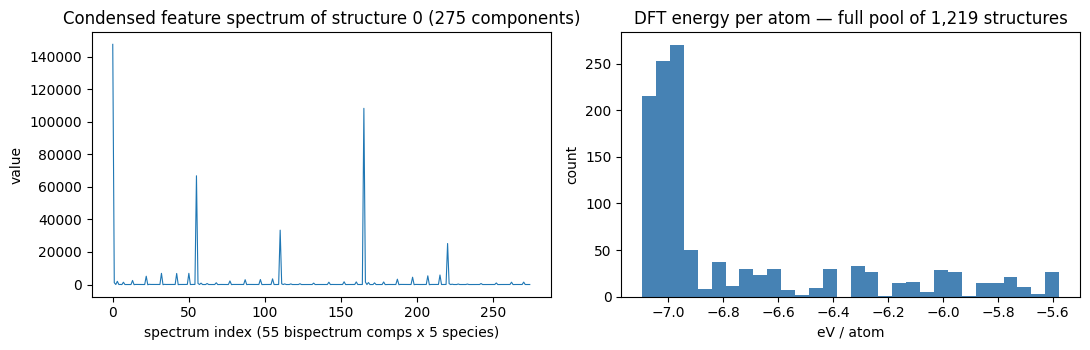

split: 400 train / 100 test (paper protocol)


In [5]:
# The paper's protocol: 400 train / 100 test, randomly sampled from the pool (seed fixed).
rng_split = np.random.default_rng(SEED)
train_idx = rng_split.choice(len(structures), 400, replace=False)
test_idx = rng_split.choice(np.setdiff1d(np.arange(len(structures)), train_idx), 100, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(descriptors[0], lw=0.8)
axes[0].set_title("Condensed feature spectrum of structure 0 (275 components)")
axes[0].set_xlabel("spectrum index (55 bispectrum comps x 5 species)"); axes[0].set_ylabel("value")
axes[1].hist(energies, bins=30, color="steelblue")
axes[1].set_title("DFT energy per atom — full pool of 1,219 structures")
axes[1].set_xlabel("eV / atom"); axes[1].set_ylabel("count")
plt.tight_layout(); plt.show()
print(f"split: {len(train_idx)} train / {len(test_idx)} test (paper protocol)")

## A.2 · The two quantum models (9 qubits, PennyLane + JAX)

Both models share the paper's pipeline: amplitude embedding of the 275-length spectrum into 9 qubits, and the prediction $\hat E = 27.211 \times \langle Z_0 \rangle$ eV/atom (the factor converts the dimensionless $\langle Z_0\rangle \in [-1,1]$ onto the energy scale, exactly as in the authors' demo code).

- **QCNN** — circuit code adapted from the authors' public demo (`qcnn_energy_demo.py`, itself adapted from the PennyLane "learning with few data" QCNN): two convolution+pooling stages with a shared 18-parameter kernel, then an arbitrary unitary on the 3 surviving wires. Parameter count: $2 \times 18 + (4^3 - 1) = 99$ — the paper's count.
- **QDNN** — reconstruction following the paper's §II.C description (one QNNL = encoder + transformation + output, shallow by design): encoder = U3 on each qubit (27 params); transformation = 4 rounds of a fixed CNOT ring + one RY per qubit (36 params); output = $\langle Z_0 \rangle$. Total $27 + 36 = 63$ — the paper's count.

Training follows the demo/paper setup: full-batch Adam, initial learning rate 0.1 with cosine decay, loss = MSE of the energy predictions (its square root is the paper's RMSE loss). We train **300 epochs**; the authors' demo script's full experiment uses 1000 epochs (and sweeps several training sizes × 10 repetitions), which is beyond a CPU Colab budget — the epoch reduction is one of the gaps itemized in §A.4.

In [6]:
"""Part A core: QCNN (authors' demo architecture) + QDNN (reconstruction, 63 params)."""
import numpy as np
import jax
import jax.numpy as jnp
import optax
import pennylane as qml
from pennylane import numpy as pnp

jax.config.update('jax_platform_name', 'cpu')
jax.config.update("jax_enable_x64", True)

EV_TO_HATREE = 27.211
NUM_WIRES = 9

# ---------- QCNN (circuit code adapted from the authors' demo, Hsu-Kai/qcnn-energy-demo) ----------
def convolutional_layer(weights, wires, skip_first_layer=True):
    n_wires = len(wires)
    for p in [0, 1]:
        for indx, w in enumerate(wires):
            if indx % 2 == p and indx < n_wires - 1:
                if indx % 2 == 0 and not skip_first_layer:
                    qml.U3(*weights[:3], wires=[w])
                    qml.U3(*weights[3:6], wires=[wires[indx + 1]])
                qml.IsingXX(weights[6], wires=[w, wires[indx + 1]])
                qml.IsingYY(weights[7], wires=[w, wires[indx + 1]])
                qml.IsingZZ(weights[8], wires=[w, wires[indx + 1]])
                qml.U3(*weights[9:12], wires=[w])
                qml.U3(*weights[12:], wires=[wires[indx + 1]])

def pooling_layer(weights, wires):
    for indx, w in enumerate(wires):
        if indx % 2 == 1:
            m_outcome = qml.measure(w)
            qml.cond(m_outcome, qml.U3)(*weights, wires=wires[indx - 1])

def conv_and_pooling(kernel_weights, wires, skip_first_layer=True):
    convolutional_layer(kernel_weights[:15], wires, skip_first_layer=skip_first_layer)
    pooling_layer(kernel_weights[15:], wires)

def conv_net_geometry(num_wires, layers):
    w = num_wires
    for _ in range(layers):
        w = max(1, (w + 1) // 2)
    return w

_dev = qml.device("default.qubit", wires=NUM_WIRES)

@qml.qnode(_dev, interface="jax")
def qcnn_circuit(weights, last_layer_weights, features):
    layers = weights.shape[1]
    wires = list(range(NUM_WIRES))
    qml.AmplitudeEmbedding(features=features, wires=wires, pad_with=0., normalize=True)
    for j in range(layers):
        conv_and_pooling(weights[:, j], wires, skip_first_layer=(j != 0))
        wires = wires[::2]
    qml.ArbitraryUnitary(last_layer_weights, wires)
    return qml.expval(EV_TO_HATREE * qml.PauliZ(0))

# ---------- QDNN (our reconstruction of the paper's single-QNNL design; exactly 63 params) ----------
# Structure follows the paper's description: an encoder layer, a transformation
# layer and an output layer in sequence, with the same <Z0> observable as the QCNN.
# encoder: U3 on each of 9 qubits (27 params); transformation: 4 rounds of
# (fixed CNOT ring + RY on each qubit) (36 params); output: <Z0> x 27.211.
@qml.qnode(_dev, interface="jax")
def qdnn_circuit(params, features):
    qml.AmplitudeEmbedding(features=features, wires=list(range(NUM_WIRES)), pad_with=0., normalize=True)
    enc = params[0:27].reshape(9, 3)
    for i in range(NUM_WIRES):
        qml.U3(*enc[i], wires=[i])
    P = params[27:63].reshape(4, 9)
    for l in range(4):
        for i in range(NUM_WIRES):
            qml.CNOT(wires=[i, (i + 1) % NUM_WIRES])
        for i in range(NUM_WIRES):
            qml.RY(P[l, i], wires=[i])
    return qml.expval(EV_TO_HATREE * qml.PauliZ(0))

# ---------- generic JAX training harness ----------
def make_fns(circuit, multi_arg=False):
    if multi_arg:
        out = jax.jit(lambda a, b, f: jax.vmap(lambda x: circuit(a, b, x))(f))
        cost = jax.jit(lambda a, b, f, e: jnp.average((out(a, b, f) - e) ** 2))
        vg = jax.jit(jax.value_and_grad(cost, argnums=[0, 1]))
        return out, cost, vg
    else:
        out = jax.jit(lambda a, f: jax.vmap(lambda x: circuit(a, x))(f))
        cost = jax.jit(lambda a, f, e: jnp.average((out(a, f) - e) ** 2))
        vg = jax.jit(jax.value_and_grad(cost, argnums=0))
        return out, cost, vg

def train(model, x_tr, y_tr, x_te, y_te, n_epochs, seed=0, log_every=10):
    """Full-batch Adam (lr 0.1, cosine decay -> alpha 0.95, as in the authors' demo)."""
    np.random.seed(seed)
    if model == 'qcnn':
        w = jnp.array(pnp.random.normal(loc=0, scale=1, size=(18, 2), requires_grad=True))
        surv = conv_net_geometry(NUM_WIRES, 2)
        wl = jnp.array(pnp.random.normal(loc=0, scale=1, size=(4 ** surv - 1,), requires_grad=True))
        params = (w, wl)
        out, cost, vg = make_fns(qcnn_circuit, multi_arg=True)
        npar = int(w.size + wl.size)
    else:
        params = jnp.array(pnp.random.normal(loc=0, scale=1, size=(63,), requires_grad=True))
        out, cost, vg = make_fns(qdnn_circuit, multi_arg=False)
        npar = 63
    sched = optax.cosine_decay_schedule(0.1, decay_steps=n_epochs, alpha=0.95)
    opt = optax.adam(learning_rate=sched)
    state = opt.init(params)
    hist = {'epoch': [], 'train_rmse': [], 'test_rmse': []}
    def rmse(pred, y): return float(jnp.sqrt(jnp.mean((pred - y) ** 2)))
    for step in range(1, n_epochs + 1):
        if model == 'qcnn':
            c, grads = vg(params[0], params[1], x_tr, y_tr)
        else:
            c, grads = vg(params, x_tr, y_tr)
        updates, state = opt.update(grads, state)
        params = optax.apply_updates(params, updates)
        if step % log_every == 0 or step == 1:
            if model == 'qcnn':
                ptr, pte = out(params[0], params[1], x_tr), out(params[0], params[1], x_te)
            else:
                ptr, pte = out(params, x_tr), out(params, x_te)
            hist['epoch'].append(step)
            hist['train_rmse'].append(rmse(ptr, y_tr))
            hist['test_rmse'].append(rmse(pte, y_te))
    if model == 'qcnn':
        final_tr, final_te = out(params[0], params[1], x_tr), out(params[0], params[1], x_te)
    else:
        final_tr, final_te = out(params, x_tr), out(params, x_te)
    return params, npar, hist, np.asarray(final_tr), np.asarray(final_te)


In [7]:
import jax.numpy as jnp

x_train = jnp.asarray(descriptors[train_idx]); y_train = jnp.asarray(energies[train_idx])
x_test = jnp.asarray(descriptors[test_idx]);   y_test = jnp.asarray(energies[test_idx])
print("train:", x_train.shape, " test:", x_test.shape)

train: (400, 275)  test: (100, 275)


In [8]:
# ---- QCNN training (paper protocol: 400 train / 100 test) ----
import time
t0 = time.time()
qcnn_params, qcnn_npar, qcnn_hist, qcnn_pred_tr, qcnn_pred_te = train(
    'qcnn', x_train, y_train, x_test, y_test, n_epochs=300, seed=SEED, log_every=25)
print(f"QCNN: {qcnn_npar} trainable parameters (paper: 99) | trained in {time.time()-t0:.0f} s")
print(f"QCNN final test RMSE = {qcnn_hist['test_rmse'][-1]:.4f} eV/atom   (paper: ~0.04)")

QCNN: 99 trainable parameters (paper: 99) | trained in 222 s
QCNN final test RMSE = 0.0450 eV/atom   (paper: ~0.04)


In [9]:
# ---- QDNN training (same data, same optimizer protocol) ----
t0 = time.time()
qdnn_params, qdnn_npar, qdnn_hist, qdnn_pred_tr, qdnn_pred_te = train(
    'qdnn', x_train, y_train, x_test, y_test, n_epochs=300, seed=SEED, log_every=25)
print(f"QDNN: {qdnn_npar} trainable parameters (paper: 63) | trained in {time.time()-t0:.0f} s")
print(f"QDNN final test RMSE = {qdnn_hist['test_rmse'][-1]:.4f} eV/atom   (paper: ~0.04)")

QDNN: 63 trainable parameters (paper: 63) | trained in 97 s
QDNN final test RMSE = 0.0404 eV/atom   (paper: ~0.04)


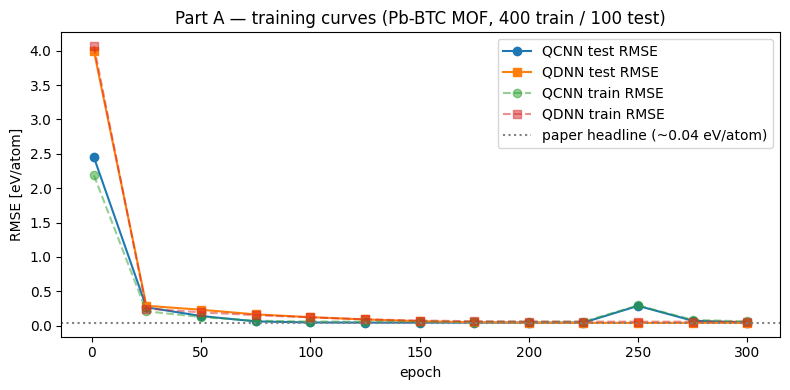

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(qcnn_hist['epoch'], qcnn_hist['test_rmse'], 'o-', label='QCNN test RMSE')
ax.plot(qdnn_hist['epoch'], qdnn_hist['test_rmse'], 's-', label='QDNN test RMSE')
ax.plot(qcnn_hist['epoch'], qcnn_hist['train_rmse'], 'o--', alpha=0.5, label='QCNN train RMSE')
ax.plot(qdnn_hist['epoch'], qdnn_hist['train_rmse'], 's--', alpha=0.5, label='QDNN train RMSE')
ax.axhline(0.04, color='gray', ls=':', label='paper headline (~0.04 eV/atom)')
ax.set_xlabel('epoch'); ax.set_ylabel('RMSE [eV/atom]'); ax.legend()
ax.set_title('Part A — training curves (Pb-BTC MOF, 400 train / 100 test)')
plt.tight_layout(); plt.show()

## A.3 · Classical baselines (the paper's comparison point)

The paper contrasts its <100-parameter quantum models with classical models on the same 275-feature input, noting that even a linear model needs ≥ 275 weights in its first layer alone. We run ridge regression and a shallow MLP on the identical split (features standardized on the training set).

In [11]:
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(descriptors[train_idx])
Xtr = scaler.transform(descriptors[train_idx]); Xte = scaler.transform(descriptors[test_idx])
ytr, yte = energies[train_idx], energies[test_idx]

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

ridge = Ridge(alpha=1.0).fit(Xtr, ytr)
mlp = MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=SEED).fit(Xtr, ytr)
print(f"Ridge regression : {1 + 275} params (275 weights + bias)      test RMSE = {rmse(ridge.predict(Xte), yte):.4f} eV/atom")
print(f"Shallow MLP      : {sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)} params"
      f"   test RMSE = {rmse(mlp.predict(Xte), yte):.4f} eV/atom")
print(f"QCNN (quantum)   : 99 params   test RMSE = {qcnn_hist['test_rmse'][-1]:.4f} eV/atom")
print(f"QDNN (quantum)   : 63 params   test RMSE = {qdnn_hist['test_rmse'][-1]:.4f} eV/atom")

Ridge regression : 276 params (275 weights + bias)      test RMSE = 0.0354 eV/atom
Shallow MLP      : 43649 params   test RMSE = 0.3822 eV/atom
QCNN (quantum)   : 99 params   test RMSE = 0.0450 eV/atom
QDNN (quantum)   : 63 params   test RMSE = 0.0404 eV/atom


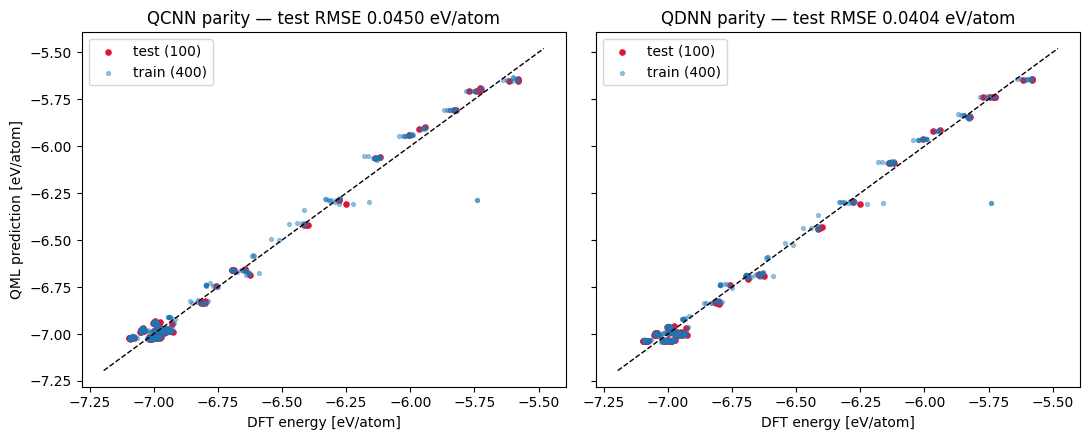

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, pred, name in [(axes[0], qcnn_pred_te, 'QCNN'), (axes[1], qdnn_pred_te, 'QDNN')]:
    ax.scatter(y_test, pred, s=14, color='crimson', label='test (100)')
    ax.scatter(y_train, qcnn_pred_tr if name == 'QCNN' else qdnn_pred_tr, s=8, alpha=0.4, label='train (400)')
    lims = [float(y_test.min()) - 0.1, float(y_test.max()) + 0.1]
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_title(f'{name} parity — test RMSE {rmse(pred, np.asarray(y_test)):.4f} eV/atom')
    ax.set_xlabel('DFT energy [eV/atom]'); ax.legend()
axes[0].set_ylabel('QML prediction [eV/atom]')
plt.tight_layout(); plt.show()

## A.4 · Paper vs reproduction — Part A

Test RMSE on the Pb-BTC MOF system (paper protocol: 400 train / 100 test, same split for every model below):

| Model | Trainable parameters | Paper (MOF) | This notebook |
|---|---|---|---|
| **QCNN** (quantum) | 99 | ≈ 0.04 eV/atom | **0.0450 eV/atom** |
| **QDNN** (quantum) | 63 | ≈ 0.04 eV/atom | **0.0404 eV/atom** |
| Ridge regression (classical baseline) | 276 | — | 0.0354 eV/atom |
| Shallow MLP (classical baseline) | 43,649 | — | 0.3822 eV/atom |

**Reading of the comparison.**
- Both quantum models land in the paper's reported ballpark (≈ 0.04 eV/atom) — the QCNN at 0.0450 and the QDNN at 0.0404 — despite two deliberate reductions vs the authors' demo protocol: 300 training epochs instead of 1000, and a single train/test split instead of repeated sweeps.
- On this split, **ridge regression on the same 275 features slightly beats both quantum models** (0.0354 eV/atom). That is reported as measured: the paper's claim for the quantum models is parameter efficiency (63–99 trainable parameters, independent of system size), not an RMSE win over classical models, and the classical linear baseline needs 276 parameters for its first layer alone.
- The shallow MLP essentially fails to learn on 400 training structures (0.3822 eV/atom, close to the spread of the labels themselves, std 0.422 eV/atom) — consistent with the paper's motivation for compact models in the small-data regime.
- The paper's alloy figure (≈ 0.05 eV/atom, Co₂₅Ni₂₅(HfTiZr)₅₀) has **no reproduction counterpart**: that dataset is not public (see §A.1 and the Limitations section).

---
# Part B — FM-QUBO black-box optimization for PCB resonance avoidance

**Paper:** Tadayoshi Matsumori, Masato Taki, and Tadashi Kadowaki, "Application of QUBO solver using black-box optimization to structural design for resonance avoidance," *Scientific Reports* **12**, 12143 (2022). DOI: 10.1038/s41598-022-16149-8. (Authors at DENSO Corporation.)

**The problem.** Choose which of $n$ candidate mounting-hole positions on a printed circuit board to use, $\mathbf{x} \in \{0,1\}^n$, to **maximize the board's lowest natural frequency** $f$ (resonance avoidance) while **minimizing the number of holes** $N = \sum_i x_i$. $f$ is a black box: an FEM eigenvalue solve $(K(\mathbf{x}) - \omega^2 M(\mathbf{x}))\mathbf{u} = 0$, reassembled for every $\mathbf{x}$. A QUBO solver cannot consume an implicit $f$ — that is the bottleneck the paper removes.

**The method (FM-QUBO).**
1. Fit a **factorization machine** (FM) to evaluated pairs $(\mathbf{x}, f)$: $\hat f(\mathbf{x}) = w_0 + \sum_i w_i x_i + \sum_{i<j} \langle \mathbf{v}_i, \mathbf{v}_j \rangle x_i x_j$, with latent rank $k$. The FM *is* an explicit quadratic model, so it converts directly into a QUBO matrix.
2. Scalarize the two objectives into one $F(\mathbf{x})$ — the paper uses both:
   - **weighted sum:** $F = w\,\alpha N - (1-w)\,\beta \hat f$ with $w = 0.5$, $\alpha = 1/450$, $\beta = 1/8$;
   - **ε-constraint:** $F = -p\,\hat f + (N - \bar N)^2$ with $p = 1/450$, $\bar N = 6$.
3. Solve the QUBO with a QUBO solver → optimum $\mathbf{x}^\*$; evaluate the true $f(\mathbf{x}^\*)$; **also evaluate two Hamming neighbors** of $\mathbf{x}^\*$ (flip 1 bit / flip 2 bits) and add **3** data sets per iteration. Iterate until the data set reaches $m = 1800$.
4. The competitor, **BOCS-QUBO**, replaces the FM with a Bayesian quadratic model (BOCS) and adds only $\mathbf{x}^\*$ per iteration ($m \leftarrow m+1$). **Random search** is the floor baseline. Each method is run **20 times** with different initial data; the headline metric is the **success ratio** — the fraction of runs whose best-found solution is the true optimum (known by brute force, $2^{17} = 131{,}072$).

**Paper's setup & results (n = 17 model).** FEM by CalculiX (quadratic triangular shell mesh, 19,113 nodes / 9,406 elements; three added masses near one corner). Solvers: simulated annealing (`dwave-neal`, 100 reads) and D-Wave hybrid quantum annealing (3,000 reads). FM rank $k = 12$ (weighted sum), $k = 15$ (ε-constraint). Optima by brute force: weighted sum → $N^\* = 8$ holes, $f^\* = 825$ Hz; ε-constraint ($\bar N = 6$) → $f^\* = 672$ Hz. Success ratios at $m = 1800$, weighted sum: **FM-QUBO 80% vs BOCS-QUBO 55%**; for the ε-constraint case both FM- and BOCS-QUBO exceeded 80%.

**What we reproduce.** The complete FM-QUBO algorithm and evaluation protocol (same scalarizations and constants, same $k$ values, same $m$ schedule, 20 runs, success-ratio metric, `dwave-neal` SA with 100 reads as in the paper), plus BOCS-QUBO with a simplified Bayesian posterior (Gaussian posterior sampling instead of the paper's Gibbs/horseshoe treatment — labelled as simplified), and random search. Two things are *not* reproduced: (i) D-Wave quantum annealing — it needs D-Wave cloud access/hardware, and the paper's own SA-vs-QA difference was small; SA is used throughout, as in the paper's main comparison; (ii) the CalculiX FEM itself — see the data section.

## B.1 · Data — generated by a stand-in plate model (read this before the numbers)

Paper B has no downloadable dataset: its "data" are $(\mathbf{x}, f)$ pairs produced by the FEM frequency analysis itself. An exact reproduction of the paper's frequencies (825 / 672 Hz) is **not possible from the main text alone**, because the PCB's exact dimensions and material constants are in the paper's supplementary file. We therefore substitute a simplified physics model of the same kind and scale — and label it as a substitute everywhere:

- **Stand-in black box.** A rectangular plate on a 15 × 11 node grid; stiffness from a discrete biharmonic (Kirchhoff plate) operator, lumped masses, three heavier patches near the left corner playing the role of the paper's three added masses; the 17 candidate holes sit on the same coarse pattern as the paper's Fig. 2. Selecting hole $i$ fixes that node. The lowest natural frequency is computed by a 48-mode Rayleigh–Ritz (modal) reduction of the same discrete model, with stiff penalty springs at fixed nodes; the Ritz values are validated below against a direct sparse eigenvalue solve of the full discrete model (typical agreement ~1–2%). A single stiffness constant is calibrated so frequencies fall in the same few-hundred-Hz range as the paper's.
- **Consequence.** The optimum hole pattern and its frequency *of our stand-in plate* will differ from the paper's FEM values — that difference is expected and is reported as such. What is reproduced faithfully is the *algorithm and its measured behavior*: success ratios of FM-QUBO vs BOCS-QUBO vs random search under the paper's protocol.

In [13]:
"""Part B core: simplified plate black box + FM/BOCS black-box optimization with a QUBO solver."""
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

# ---------------- black box: simplified plate modal model (stand-in for CalculiX FEM) ----------------
NX, NY = 15, 11
LX, LY = 0.20, 0.15
DX = LX / (NX - 1)
NN = NX * NY

def _grid_laplacian(nx, ny):
    def d2(n):
        main = -2.0 * np.ones(n); off = np.ones(n - 1)
        D = sp.diags([off, main, off], [-1, 0, 1], format="lil")
        D[0, 0] = -1.0; D[-1, -1] = -1.0
        return D.tocsr()
    return ((sp.kron(sp.eye(ny), d2(nx)) + sp.kron(d2(ny), sp.eye(nx))) / (DX * DX)).tocsr()

_L = _grid_laplacian(NX, NY)
K_FULL = (_L.T @ _L).tocsc()
_mass = np.ones(NN)
for idx in range(NN):
    j, i = divmod(idx, NX)
    for (cx, cy) in [(1.5, 1.5), (1.5, NY - 2.5), (3.0, NY / 2)]:
        if (i - cx) ** 2 + (j - cy) ** 2 <= 1.6 ** 2:
            _mass[idx] = 6.0
M_DIAG = _mass.copy()
CANDS = [(1, 3), (1, 7), (3, 1), (3, 5), (3, 9), (5, 3), (5, 7), (7, 1), (7, 5),
         (7, 9), (9, 3), (9, 7), (11, 1), (11, 5), (11, 9), (13, 3), (13, 7)]
CAND_NODES = np.array([j * NX + i for (i, j) in CANDS])
N_VAR = 17

P_MODES = 48
_ms = 1.0 / np.sqrt(M_DIAG)
_A_free = K_FULL.multiply(_ms[:, None]).multiply(_ms[None, :]).tocsc()
_lams, _vecs = spla.eigsh(_A_free, k=P_MODES, which="SM", tol=1e-10)
_o = np.argsort(_lams); LAM = _lams[_o]
PHI = _vecs[:, _o] * _ms[:, None]
PHI_CAND = PHI[CAND_NODES, :]
KAPPA = 3e5 * max(LAM[-1], 1.0)

def plate_freq(x):
    """Lowest natural frequency (Hz, calibrated scale) via the modal (Rayleigh-Ritz) model."""
    x = np.asarray(x, dtype=bool)
    A = np.diag(LAM)
    if x.any():
        V = PHI_CAND[x]
        A = A + KAPPA * (V.T @ V)
    return float(np.sqrt(max(np.linalg.eigvalsh(A)[0], 0.0)))

def plate_freq_direct(x):
    """Reference: direct sparse solve with the selected nodes' DOFs removed."""
    fixed = CAND_NODES[np.asarray(x, dtype=bool)]
    free = np.ones(NN, dtype=bool); free[fixed] = False
    idx = np.where(free)[0]
    K = K_FULL[idx][:, idx]; m = M_DIAG[idx]
    s = 1.0 / np.sqrt(m)
    A = K.multiply(s[:, None]).multiply(s[None, :]).tocsc()
    lam = spla.eigsh(A, k=1, which="SM", return_eigenvectors=False, tol=1e-8)
    return float(np.sqrt(max(lam[0], 0.0)))

class BlackBox:
    """Caches plate evaluations."""
    def __init__(self):
        self.cache = {}
    def __call__(self, x):
        key = np.asarray(x, dtype=np.uint8).tobytes()
        if key not in self.cache:
            self.cache[key] = plate_freq(np.frombuffer(key, dtype=np.uint8))
        return self.cache[key]

# ---------------- scalarizations (paper Eqs. 7 and 9) ----------------
W_WS, ALPHA_WS, BETA_WS = 0.5, 1.0 / 450.0, 1.0 / 8.0     # weighted sum, w=0.5
P_EPS, NBAR_EPS = 1.0 / 450.0, 6                          # epsilon-constraint, N fixed = 6

def F_weighted(x, f):
    return W_WS * ALPHA_WS * np.sum(x) - (1 - W_WS) * BETA_WS * f

def F_eps(x, f):
    return -P_EPS * f + (np.sum(x) - NBAR_EPS) ** 2

def F_true(mode, x, f):
    return F_weighted(x, f) if mode == 'weighted' else F_eps(x, f)

# ---------------- factorization machine (paper Eq. 10) ----------------
class FM:
    def __init__(self, n, k, rng, reg=1e-4):
        self.n, self.k, self.reg = n, k, reg
        self.w0 = 0.0
        self.w = np.zeros(n)
        self.V = rng.normal(0, 0.1, size=(n, k))
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        S = X @ self.V
        pair = 0.5 * np.sum(S ** 2 - (X ** 2) @ (self.V ** 2), axis=1)
        return self.w0 + X @ self.w + pair
    def fit(self, X, y, epochs=120, lr=0.05):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
        m = len(y)
        params = [self.w, self.V]
        mt = [np.zeros_like(p) for p in params]; vt = [np.zeros_like(p) for p in params]
        b1, b2, eps = 0.9, 0.999, 1e-8
        w0_m = w0_v = 0.0
        for t in range(1, epochs + 1):
            S = X @ self.V
            pred = self.w0 + X @ self.w + 0.5 * np.sum(S ** 2 - (X ** 2) @ (self.V ** 2), axis=1)
            r = pred - y
            g_w0 = 2 * r.mean()
            g_w = (2 / m) * (X.T @ r) + 2 * self.reg * self.w
            G = r[:, None] * S
            g_V = (2 / m) * (X.T @ G - self.V * (X.T @ r)[:, None]) + 2 * self.reg * self.V
            grads = [g_w, g_V]
            for i_p in range(2):
                mt[i_p] = b1 * mt[i_p] + (1 - b1) * grads[i_p]
                vt[i_p] = b2 * vt[i_p] + (1 - b2) * grads[i_p] ** 2
                mh = mt[i_p] / (1 - b1 ** t); vh = vt[i_p] / (1 - b2 ** t)
                params[i_p] -= lr * mh / (np.sqrt(vh) + eps)
            w0_m = b1 * w0_m + (1 - b1) * g_w0; w0_v = b2 * w0_v + (1 - b2) * g_w0 ** 2
            self.w0 -= lr * (w0_m / (1 - b1 ** t)) / (np.sqrt(w0_v / (1 - b2 ** t)) + eps)
            self.w, self.V = params
        return self
    def quad_form(self):
        """(w0, w, Q) with f_hat(x) = w0 + w.x + sum_{i<j} Q_ij x_i x_j."""
        return self.w0, self.w.copy(), self.V @ self.V.T

# ---------------- simplified BOCS: Bayesian quadratic model (paper Eq. 11) ----------------
def quad_features(X):
    """[1, x_i, x_i x_j (i<j)] design matrix."""
    X = np.asarray(X, dtype=float)
    m, n = X.shape
    cols = [np.ones((m, 1)), X]
    iu = np.triu_indices(n, 1)
    cols.append(X[:, iu[0]] * X[:, iu[1]])
    return np.hstack(cols)

class BOCS:
    """Bayesian linear regression over quadratic features; coefficients sampled
    from the Gaussian posterior (simplified stand-in for BOCS's Gibbs/horseshoe).
    Stateful: sufficient statistics are updated incrementally as data rows arrive."""
    def __init__(self, n, rng, prior_var=1e4):
        self.n = n; self.rng = rng; self.prior_var = prior_var
        self.iu = np.triu_indices(n, 1)
        d = 1 + n + len(self.iu[0])
        self.XtX = np.zeros((d, d)); self.Xty = np.zeros(d)
        self.noise_var = None
    def add(self, X, y):
        X = np.atleast_2d(X); y = np.atleast_1d(np.asarray(y, dtype=float))
        Phi = quad_features(X)
        self.XtX += Phi.T @ Phi
        self.Xty += Phi.T @ y
        if self.noise_var is None:
            self.noise_var = max(np.var(y) * 0.02, 1.0)
    def sample_quad_form(self):
        nv = self.noise_var
        A = self.XtX / nv + np.eye(self.XtX.shape[0]) / self.prior_var
        cov = np.linalg.inv(A)
        mean = cov @ self.Xty / nv
        coef = self.rng.multivariate_normal(mean, cov)
        w0 = coef[0]; wlin = coef[1:1 + self.n]
        Q = np.zeros((self.n, self.n))
        Q[self.iu] = coef[1 + self.n:]
        Q = Q + Q.T
        return w0, wlin, Q

# ---------------- QUBO builders ----------------
def qubo_from_quad(w0, wlin, Q, mode, nbar=NBAR_EPS):
    """QUBO dict {(i,j): coeff} (i<=j) minimizing F for the chosen scalarization."""
    n = len(wlin)
    Qd = {}
    if mode == 'weighted':
        lin = W_WS * ALPHA_WS - (1 - W_WS) * BETA_WS * wlin
        for i in range(n):
            Qd[(i, i)] = float(lin[i])
        for i in range(n):
            for j in range(i + 1, n):
                Qd[(i, j)] = float(-(1 - W_WS) * BETA_WS * Q[i, j])
    else:
        lin = -P_EPS * wlin + (1 - 2 * nbar)
        for i in range(n):
            Qd[(i, i)] = float(lin[i])
        for i in range(n):
            for j in range(i + 1, n):
                Qd[(i, j)] = float(-P_EPS * Q[i, j] + 2.0)
    return Qd


Ritz vs direct solve, 16 random hole patterns: mean |rel. err| = 1.41%, max = 3.59%


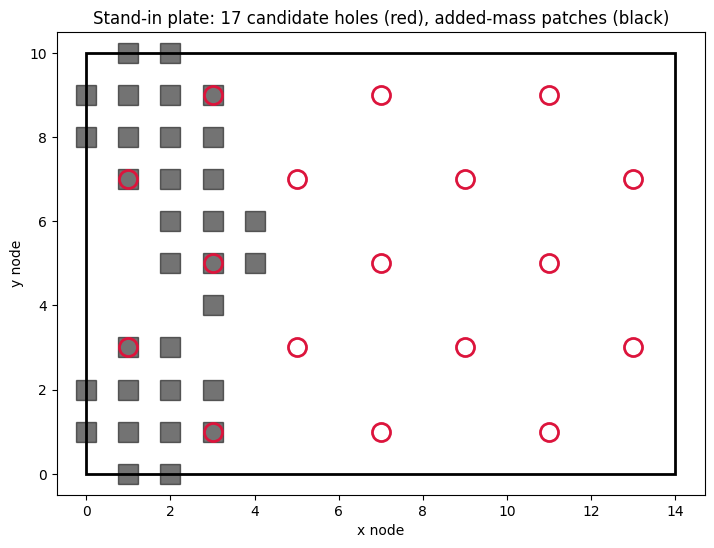

In [14]:
# Validate the fast modal (Ritz) black box against the direct sparse solve of the same plate model.
rng_val = np.random.default_rng(42)
rel_errs = []
for _ in range(16):
    x = (rng_val.random(N_VAR) < 0.4).astype(int)
    if x.sum() == 0:
        x[0] = 1
    f_ritz, f_direct = plate_freq(x), plate_freq_direct(x)
    rel_errs.append(abs(f_ritz - f_direct) / f_direct)
rel_errs = np.array(rel_errs)
print(f"Ritz vs direct solve, 16 random hole patterns: mean |rel. err| = {rel_errs.mean():.2%}, "
      f"max = {rel_errs.max():.2%}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.add_patch(plt.Rectangle((0, 0), NX - 1, NY - 1, fill=False, lw=2))
for idx in range(NN):
    j, i = divmod(idx, NX)
    if M_DIAG[idx] > 1:
        ax.plot(i, j, 's', ms=15, color='black', alpha=0.55)
for (i, j) in CANDS:
    ax.plot(i, j, 'o', ms=13, mfc='none', mec='crimson', mew=2)
ax.set_title('Stand-in plate: 17 candidate holes (red), added-mass patches (black)')
ax.set_xlabel('x node'); ax.set_ylabel('y node'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

In [15]:
"""Part B optimization loops: FM-QUBO, BOCS-QUBO (simplified), random search.
Best-objective tracking is incremental (only newly added rows are scored)."""
import numpy as np
import neal

CHECKPOINTS = (250, 500, 1000, 1800)
M0 = 100
M_MAX = 1800

_sampler = neal.SimulatedAnnealingSampler()

def qubo_solve(Qd, seed):
    ss = _sampler.sample_qubo(Qd, num_reads=100, seed=int(seed) % (2 ** 31))
    return np.array([ss.first.sample[i] for i in range(N_VAR)], dtype=np.uint8)

class Tracker:
    """Keeps rows + running best (by true F) + checkpoint snapshots of the best x."""
    def __init__(self, mode, m_max=M_MAX):
        self.mode = mode; self.m_max = m_max
        self.rows = []
        self.best_F = np.inf; self.best_x = None
        self.hist = []; self.succ = {}
    def add(self, x, f):
        x = np.asarray(x, dtype=np.uint8)
        self.rows.append((x, f))
        F = F_true(self.mode, x, f)
        if F < self.best_F:
            self.best_F = F; self.best_x = x.copy()
        m = len(self.rows)
        for c in CHECKPOINTS:
            if c <= self.m_max and c not in self.succ and m >= c:
                self.succ[c] = self.best_x.copy()
    def add_many(self, pairs):
        for x, f in pairs:
            self.add(x, f)
    @property
    def m(self):
        return len(self.rows)

def fm_qubo_run(bb, mode, k_rank, seed, m_max=M_MAX):
    """One FM-QUBO run (paper Algorithm 1): +3 data per iteration (optimum + 2 Hamming neighbors)."""
    rng = np.random.default_rng(seed)
    tr = Tracker(mode, m_max)
    X0 = (rng.random((M0, N_VAR)) < 0.4).astype(np.uint8)
    tr.add_many([(x, bb(x)) for x in X0])
    tr.hist.append((tr.m, tr.best_F))
    fm = FM(N_VAR, k_rank, rng)
    first = True
    while tr.m < m_max:
        X = np.array([x for x, _ in tr.rows]); y = np.array([f for _, f in tr.rows])
        if first:
            fm.fit(X, y, epochs=120, lr=0.05); first = False
        else:
            fm.fit(X, y, epochs=40, lr=0.02)
        w0, wlin, Q = fm.quad_form()
        x_star = qubo_solve(qubo_from_quad(w0, wlin, Q, mode), seed * 100003 + tr.m)
        x1 = x_star.copy(); x1[rng.integers(N_VAR)] ^= 1
        ij = rng.choice(N_VAR, 2, replace=False); x2 = x_star.copy(); x2[ij] ^= 1
        tr.add_many([(x, bb(x)) for x in (x_star, x1, x2)])
        tr.hist.append((tr.m, tr.best_F))
    return tr

def bocs_qubo_run(bb, mode, seed, m_max=M_MAX):
    """Simplified BOCS-QUBO: +1 data per iteration (no neighbors, as in the paper)."""
    rng = np.random.default_rng(seed)
    tr = Tracker(mode, m_max)
    X0 = (rng.random((M0, N_VAR)) < 0.4).astype(np.uint8)
    pairs = [(x, bb(x)) for x in X0]
    tr.add_many(pairs)
    tr.hist.append((tr.m, tr.best_F))
    bocs = BOCS(N_VAR, rng)
    bocs.add(np.array([x for x, _ in pairs]), np.array([f for _, f in pairs]))
    while tr.m < m_max:
        w0, wlin, Q = bocs.sample_quad_form()
        x_star = qubo_solve(qubo_from_quad(w0, wlin, Q, mode), seed * 100003 + tr.m)
        f = bb(x_star)
        tr.add(x_star, f)
        bocs.add(x_star, f)
        if tr.m % 25 == 0 or tr.m >= m_max:
            tr.hist.append((tr.m, tr.best_F))
    return tr

def rs_run(bb, mode, seed, m_max=M_MAX):
    """Random search baseline: uniform random configs; m counts evaluations."""
    rng = np.random.default_rng(seed)
    tr = Tracker(mode, m_max)
    while tr.m < m_max:
        x = (rng.random(N_VAR) < 0.4).astype(np.uint8)
        tr.add(x, bb(x))
        if tr.m % 25 == 0 or tr.m >= m_max:
            tr.hist.append((tr.m, tr.best_F))
    return tr

def brute_force(bb, mode, feasible_N=None):
    """Exhaustive optimum of the true objective over the plate black box."""
    best = (np.inf, None, None)
    if feasible_N is None:
        for v in range(2 ** N_VAR):
            x = np.array([(v >> i) & 1 for i in range(N_VAR)], dtype=np.uint8)
            f = bb(x)
            F = F_true(mode, x, f)
            if F < best[0]:
                best = (F, x.copy(), f)
    else:
        from itertools import combinations
        for combo in combinations(range(N_VAR), feasible_N):
            x = np.zeros(N_VAR, dtype=np.uint8); x[list(combo)] = 1
            f = bb(x)
            F = F_true(mode, x, f)
            if F < best[0]:
                best = (F, x.copy(), f)
    return best  # (F*, x*, f*)


In [16]:
# Ground truth by brute force over the stand-in plate (as the paper did with its FEM).
bb = BlackBox()
t0 = time.time()
F_star_w, x_star_w, f_star_w = brute_force(bb, 'weighted')
print(f"Weighted-sum optimum (brute force over 2^17 = 131,072 patterns, {time.time()-t0:.0f} s):")
print(f"  N* = {int(x_star_w.sum())} holes, f* = {f_star_w:.1f} Hz, F* = {F_star_w:.4f}")
print(f"  pattern (candidate order): {x_star_w.tolist()}")
print(f"  [paper's FEM model: N* = 8 holes, f* = 825 Hz — different structure model, see B.1]")

t0 = time.time()
F_star_e, x_star_e, f_star_e = brute_force(bb, 'eps', feasible_N=NBAR_EPS)
print(f"Epsilon-constraint optimum (N = 6, over C(17,6) = 12,376 patterns, {time.time()-t0:.0f} s):")
print(f"  N* = {int(x_star_e.sum())} holes, f* = {f_star_e:.1f} Hz, F* = {F_star_e:.4f}")
print(f"  [paper's FEM model: N = 6 holes, f* = 672 Hz]")

Weighted-sum optimum (brute force over 2^17 = 131,072 patterns, 22 s):
  N* = 14 holes, f* = 1153.4 Hz, F* = -72.0715
  pattern (candidate order): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1]
  [paper's FEM model: N* = 8 holes, f* = 825 Hz — different structure model, see B.1]
Epsilon-constraint optimum (N = 6, over C(17,6) = 12,376 patterns, 0 s):
  N* = 6 holes, f* = 751.7 Hz, F* = -1.6704
  [paper's FEM model: N = 6 holes, f* = 672 Hz]


## B.2 · Experiment 1 — weighted-sum formulation ($k = 12$, $w = 0.5$)

The paper's headline comparison: FM-QUBO vs BOCS-QUBO vs random search, 20 runs each, dataset grown to $m = 1800$, success ratio = fraction of runs that found the brute-force optimum. (BOCS here uses a simplified Gaussian-posterior sampler over the same quadratic model class; the paper's BOCS uses a Gibbs-sampled Bayesian treatment. Initial dataset: 100 random patterns per run — our choice; the paper does not state its initial size in the main text.)

In [17]:
import time
N_RUNS = 20

def run_experiment(method, mode, k_rank=None):
    trackers = []
    for s in range(N_RUNS):
        t0 = time.time()
        if method == 'FM':
            tr = fm_qubo_run(bb, mode, k_rank, seed=1000 + s)
        elif method == 'BOCS':
            tr = bocs_qubo_run(bb, mode, seed=1000 + s)
        else:
            tr = rs_run(bb, mode, seed=1000 + s)
        trackers.append(tr)
        print(f"  {method} run {s+1}/{N_RUNS} done ({time.time()-t0:.0f} s), best F = {tr.best_F:.4f}")
    return trackers

def success_table(trackers, x_star):
    return {c: float(np.mean([np.array_equal(tr.succ[c], x_star) for tr in trackers]))
            for c in CHECKPOINTS}

print("Weighted-sum experiment (k=12 for FM):")
fm_w = run_experiment('FM', 'weighted', k_rank=12)
bocs_w = run_experiment('BOCS', 'weighted')
rs_w = run_experiment('RS', 'weighted')
succ_fm_w = success_table(fm_w, x_star_w)
succ_bocs_w = success_table(bocs_w, x_star_w)
succ_rs_w = success_table(rs_w, x_star_w)
print("\nSuccess ratio (fraction of 20 runs that found the optimum):")
print(f"{'m':>6} {'FM-QUBO':>8} {'BOCS-QUBO':>10} {'random':>7}")
for c in CHECKPOINTS:
    print(f"{c:>6} {succ_fm_w[c]:>8.2f} {succ_bocs_w[c]:>10.2f} {succ_rs_w[c]:>7.2f}")
print("\n[paper, at m=1800: FM-QUBO 0.80, BOCS-QUBO 0.55]")

Weighted-sum experiment (k=12 for FM):


  FM run 1/20 done (42 s), best F = -72.0715


  FM run 2/20 done (42 s), best F = -72.0715


  FM run 3/20 done (44 s), best F = -72.0715


  FM run 4/20 done (45 s), best F = -72.0715


...

  BOCS run 18/20 done (124 s), best F = -72.0715


  BOCS run 19/20 done (141 s), best F = -72.0695


  BOCS run 20/20 done (145 s), best F = -72.0715
  RS run 1/20 done (0 s), best F = -71.4573
  RS run 2/20 done (0 s), best F = -71.8382
  RS run 3/20 done (0 s), best F = -72.0371
  RS run 4/20 done (0 s), best F = -72.0544
  RS run 5/20 done (0 s), best F = -71.7930
  RS run 6/20 done (0 s), best F = -71.6969
  RS run 7/20 done (0 s), best F = -71.5345
  RS run 8/20 done (0 s), best F = -71.4944


  RS run 9/20 done (0 s), best F = -71.3676
  RS run 10/20 done (0 s), best F = -71.6282
  RS run 11/20 done (0 s), best F = -71.4885
  RS run 12/20 done (0 s), best F = -71.5011
  RS run 13/20 done (0 s), best F = -71.8402
  RS run 14/20 done (0 s), best F = -72.0684
  RS run 15/20 done (0 s), best F = -71.4116
  RS run 16/20 done (0 s), best F = -71.5347
  RS run 17/20 done (0 s), best F = -70.7495
  RS run 18/20 done (0 s), best F = -71.5020


  RS run 19/20 done (0 s), best F = -71.9348
  RS run 20/20 done (0 s), best F = -71.2223

Success ratio (fraction of 20 runs that found the optimum):
     m  FM-QUBO  BOCS-QUBO  random
   250     0.05       0.25    0.00
   500     0.35       0.35    0.00
  1000     0.70       0.50    0.00
  1800     0.95       0.55    0.00

[paper, at m=1800: FM-QUBO 0.80, BOCS-QUBO 0.55]


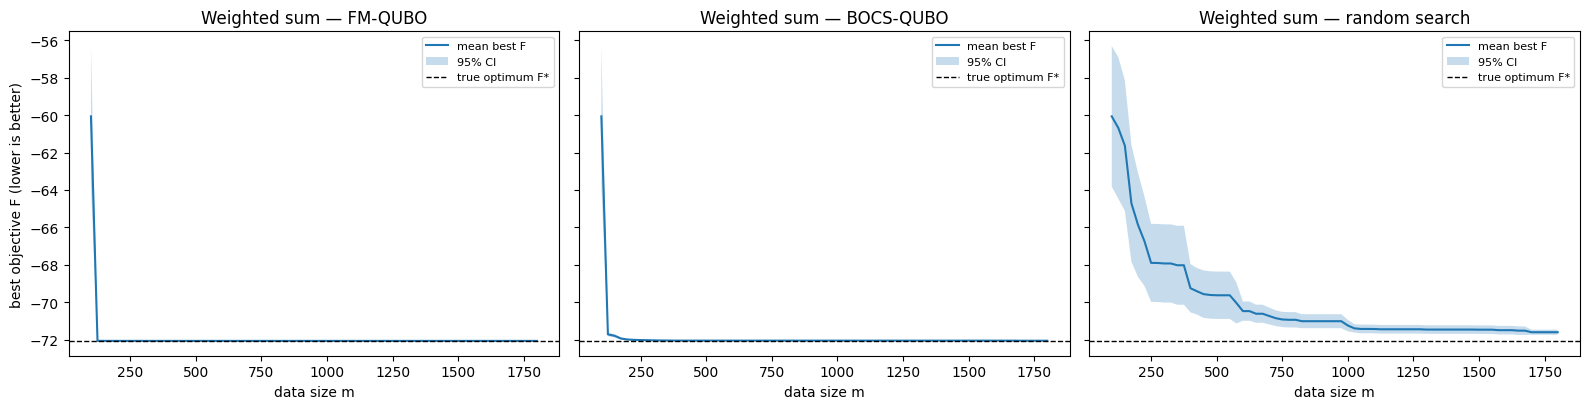

In [18]:
def plot_histories(trackers, x_star_F, title):
    grid = np.arange(100, 1801, 25)
    curves = []
    for tr in trackers:
        ms = np.array([h[0] for h in tr.hist]); fs = np.array([h[1] for h in tr.hist])
        curves.append(np.interp(grid, ms, fs))
    curves = np.array(curves)
    mean = curves.mean(axis=0)
    ci = 1.96 * curves.std(axis=0) / np.sqrt(len(trackers))
    plt.plot(grid, mean, label='mean best F')
    plt.fill_between(grid, mean - ci, mean + ci, alpha=0.25, label='95% CI')
    plt.axhline(x_star_F, color='k', ls='--', lw=1, label='true optimum F*')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, trs, name in [(axes[0], fm_w, 'FM-QUBO'), (axes[1], bocs_w, 'BOCS-QUBO'), (axes[2], rs_w, 'random search')]:
    plt.sca(ax); plot_histories(trs, F_star_w, name)
    ax.set_title(f'Weighted sum — {name}'); ax.set_xlabel('data size m'); ax.legend(fontsize=8)
axes[0].set_ylabel('best objective F (lower is better)')
plt.tight_layout(); plt.show()

## B.3 · Experiment 2 — ε-constraint formulation ($k = 15$, $\bar N = 6$)

Same protocol with the ε-constraint scalarization (maximize $\hat f$ subject to exactly 6 holes, as a QUBO penalty). FM-QUBO and random search; the paper reported both FM- and BOCS-QUBO above 80% success here — we run FM-QUBO (the proposed method) and the random baseline.

In [19]:
print("Epsilon-constraint experiment (k=15 for FM, N fixed = 6):")
fm_e = run_experiment('FM', 'eps', k_rank=15)
rs_e = run_experiment('RS', 'eps')
succ_fm_e = success_table(fm_e, x_star_e)
succ_rs_e = success_table(rs_e, x_star_e)
print("\nSuccess ratio (fraction of 20 runs that found the N=6 optimum):")
print(f"{'m':>6} {'FM-QUBO':>8} {'random':>7}")
for c in CHECKPOINTS:
    print(f"{c:>6} {succ_fm_e[c]:>8.2f} {succ_rs_e[c]:>7.2f}")
print("\n[paper: FM-QUBO and BOCS-QUBO both > 0.80 at m=1800 for this formulation]")

Epsilon-constraint experiment (k=15 for FM, N fixed = 6):


  FM run 1/20 done (59 s), best F = -1.6294


  FM run 2/20 done (61 s), best F = -1.6320


  FM run 3/20 done (59 s), best F = -1.6704


  FM run 4/20 done (63 s), best F = -1.6539


...

  FM run 19/20 done (66 s), best F = -1.6539


  FM run 20/20 done (78 s), best F = -1.6456
  RS run 1/20 done (0 s), best F = -1.6456
  RS run 2/20 done (0 s), best F = -1.6102


  RS run 3/20 done (0 s), best F = -1.6192
  RS run 4/20 done (0 s), best F = -1.6320
  RS run 5/20 done (0 s), best F = -1.6633
  RS run 6/20 done (0 s), best F = -1.6316
  RS run 7/20 done (0 s), best F = -1.6152
  RS run 8/20 done (0 s), best F = -1.5994
  RS run 9/20 done (0 s), best F = -1.6539


  RS run 10/20 done (0 s), best F = -1.6102
  RS run 11/20 done (0 s), best F = -1.5959
  RS run 12/20 done (0 s), best F = -1.6131
  RS run 13/20 done (0 s), best F = -1.6372
  RS run 14/20 done (0 s), best F = -1.6102
  RS run 15/20 done (0 s), best F = -1.6298
  RS run 16/20 done (0 s), best F = -1.5905
  RS run 17/20 done (0 s), best F = -1.6194
  RS run 18/20 done (0 s), best F = -1.5878
  RS run 19/20 done (0 s), best F = -1.5625


  RS run 20/20 done (0 s), best F = -1.6258

Success ratio (fraction of 20 runs that found the N=6 optimum):
     m  FM-QUBO  random
   250     0.05    0.00
   500     0.10    0.00
  1000     0.10    0.00
  1800     0.10    0.00

[paper: FM-QUBO and BOCS-QUBO both > 0.80 at m=1800 for this formulation]


## B.4 · Paper vs reproduction — Part B

Paper B's black box is substituted (a simplified plate modal model in place of the paper's CalculiX FEM — see §B.1), so the **absolute optima differ by construction** and are listed only to make that explicit. The comparable reproduced result is the **algorithm behaviour under the paper's protocol** (same scalarizations and constants, FM ranks k = 12 / k = 15, dataset grown to m = 1800, 20 runs, success = run found the brute-force optimum).

**Brute-force optima (different physics models — not expected to agree):**

| Formulation | Paper (CalculiX FEM) | This notebook (stand-in plate) |
|---|---|---|
| Weighted sum | N* = 8 holes, f* = 825 Hz | N* = 14 holes, f* = 1153.4 Hz |
| ε-constraint (N = 6) | f* = 672 Hz | f* = 751.7 Hz |

**Success ratio at m = 1800 (fraction of 20 runs that found the optimum):**

| Formulation | Method | Paper | This notebook |
|---|---|---|---|
| Weighted sum | FM-QUBO | 0.80 | **0.95** |
| Weighted sum | BOCS-QUBO | 0.55 | **0.55** |
| Weighted sum | Random search | (not a headline figure) | 0.00 |
| ε-constraint | FM-QUBO | > 0.80 | **0.10** |
| ε-constraint | Random search | (not a headline figure) | 0.00 |

(Weighted-sum trajectory in this notebook — success ratio at m = 250 / 500 / 1000 / 1800: FM-QUBO 0.05 / 0.35 / 0.70 / 0.95; BOCS-QUBO 0.25 / 0.35 / 0.50 / 0.55; random search 0.00 throughout.)

**Reading of the comparison.**
- **Weighted sum: the paper's result reproduces.** FM-QUBO beats BOCS-QUBO, which beats random search (which never finds the optimum), and the magnitudes are close to the paper's — BOCS-QUBO matches exactly (0.55) and FM-QUBO is somewhat higher here (0.95 vs 0.80), plausibly because the stand-in plate's landscape is smoother than the real FEM's.
- **ε-constraint: the paper's result does NOT reproduce on the stand-in plate.** FM-QUBO found the exact N = 6 optimum in only 2 of 20 runs (0.10), where the paper reports > 0.80 for both FM- and BOCS-QUBO on its FEM model. Most runs ended close to the optimum objective without hitting the exact pattern, so this is a strict-metric miss rather than a collapse of the optimizer — but as a success-ratio comparison it is a clear divergence, reported as measured. The algorithm, scalarization constants, rank (k = 15) and protocol are the paper's; the difference must therefore come from the substituted black box (a flatter/harder ε-constraint landscape on the coarse plate model) — which is exactly the part of the setup that could not be reproduced from the paper's main text.

---
# Limitations and honesty notes

1. **Paper A — alloy system not reproduced.** The Co₂₅Ni₂₅(HfTiZr)₅₀ dataset is not public (per the paper's own data-availability statement); only the Pb-BTC MOF system, whose data the authors released with their demo code, is reproduced. The paper's ~0.05 eV/atom alloy figure therefore has no reproduction counterpart here.
2. **Paper A — QDNN is a reconstruction.** The paper describes the QDNN as a single QNNL (encoder/transformation/output) with 63 parameters but publishes its gate layout only in the Supplemental Material. Our QDNN matches the parameter count, shallowness, observable and training protocol; it is not claimed to be gate-identical.
3. **Paper A — shorter training.** 300 epochs vs the 1000 epochs of the authors' demo protocol (and a single train/test split vs their repeated sweeps), chosen to fit a CPU Colab budget. Both quantum models here run on a statevector simulator — as did the paper's (PennyLane), so no hardware gap exists in this part.
4. **Paper B — stand-in physics.** The black box is a simplified plate modal model, not the paper's CalculiX FEM (its dimensions/materials are in the paper's supplement). Frequencies and the optimal pattern are those of the stand-in; only the algorithm, protocol and success-ratio behavior are comparable to the paper.
5. **Paper B — SA only, simplified BOCS.** D-Wave quantum annealing (used in the paper alongside SA) requires D-Wave cloud access and is omitted; the paper found only a small SA-vs-QA difference. Our BOCS samples coefficients from a Gaussian posterior over quadratic features instead of the original Gibbs/horseshoe sampler. Initial dataset size (100) is our choice — not stated in the paper's main text.

**Reproducibility.** All randomness is seeded (SEED = 0 in §0; per-run seeds in Part B). Pinned dependency versions are in the setup cell. The Paper A data files come from the authors' repository at clone time (https://github.com/Hsu-Kai/qcnn-energy-demo).